# Week 2 — Spiking simulation and sanity checks

Uses the weight set from `02_weights.ipynb` and the LIF module `sim/lif.py` (Shiu et al. 2024 parameters, copied from their `model.py`).

Checks, in order (each must pass before the next):
1. **Direct targets:** stimulate JO-C/E; their direct postsynaptic partners should fire.
2. **Known benchmark:** sugar GRNs (LB3b/LB3c) → proboscis motor neuron MN9
3. **Your pathway:** JO-C/E → 68 descending candidates → 81 front-leg motor neurons
4. **Shuffled control:** degree-preserving rewiring of the check 2 and 3 subnetworks

Memory: WSL is capped at 4 GB, so the checks run on subnetworks. Each build prints peak memory.

### Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BRAIN = Path.home() / 'arm_simulation/brain'     # on Colab, change only these two lines
DATA = BRAIN / 'data'
sys.path.insert(0, str(BRAIN))

from sim.lif import WeightSet, LIFNet, SHIU, peak_mem_gb, shuffle_sub, raster
from brian2 import Hz, second, prefs

ws = WeightSet(DATA / 'weights_male-cns_v1.0')
print(f"{ws.N:,} neurons, {len(ws.count):,} edges, guessed neurons: {ws.meta['guessed_neurons']:,}")
from brian2.codegen.runtime.cython_rt import CythonCodeObject
print(f"Brian2 fast C code (Cython) available: {CythonCodeObject.is_available()}")
print(f"peak memory: {peak_mem_gb():.2f} GB")

176,422 neurons, 25,862,574 edges, guessed neurons: 25,159
Brian2 fast C code (Cython) available: True
peak memory: 1.03 GB


### Cell 1: check the histamine fill

Step 2 filled 5,854 unclear neurons as histamine. That's fine if they are photoreceptor types; if non-photoreceptor types show up here, tell me.

In [2]:
h = ws.neurons[ws.neurons.guessed & (ws.neurons.nt_used == 'histamine')]
print(f"guessed as histamine: {len(h):,}")
display(h['cls'].value_counts().to_frame('neurons'))
display(h['type'].value_counts().head(15).to_frame('neurons'))

guessed as histamine: 5,789


,neurons
cls,
ol_sensory,3960
ol_intrinsic,1829


,neurons
type,
R1-R6,2627
T1,1776
R7y,416
R7_unclear,329
R7p,254
R8_unclear,156
R8y,91
Lai,53
R8p,53


### Cell 2: neuron groups

JO-C/E and the Week 1 shortlist, plus a search for the check 2 neurons (sugar GRNs and MN9). Send me the search output; the exact male-CNS type names decide check 2.

In [3]:
JO = ws.by_type(r'^JO-(C|E)', cls='cb_sensory')
print(f"JO-C/E: {len(JO)} neurons (Week 1: 335)")

shortlist = pd.read_csv(DATA / 'shortlist_week1.csv')
g2i = pd.Series(ws.neurons.index, index=ws.neurons.bodyId)
DN_cand = g2i.loc[shortlist.query("group == 'middle_descending'").bodyId].to_numpy()
LEG_MN  = g2i.loc[shortlist.query("group == 'output_T1_leg_MN'").bodyId].to_numpy()
print(f"descending candidates: {len(DN_cand)}  front-leg motor neurons: {len(LEG_MN)}")

types = ws.neurons['type'].astype(str)
sens = ws.neurons[(ws.neurons.cls == 'cb_sensory') &
                  types.str.contains(r'(?i)gr5|gr64|sugar|sweet|gust|GRN|taste|pharyn|labell')]
print(f"\ngustatory-looking sensory neurons: {len(sens)}")
display(sens['type'].value_counts().head(30).to_frame('neurons'))

mn = ws.neurons[types.str.contains(r'(?i)^MN9|mn9|proboscis')]
print(f"MN9-looking neurons: {len(mn)}")
display(mn[['bodyId', 'type', 'cls', 'nt_used']])

JO-C/E: 335 neurons (Week 1: 335)
descending candidates: 68  front-leg motor neurons: 81

gustatory-looking sensory neurons: 100


,neurons
type,
claw_tpGRN,50
BM_Taste,40
dorsal_tpGRN,10


MN9-looking neurons: 2


,bodyId,type,cls,nt_used
13273,10331,MN9,cb_motor,acetylcholine
13385,16949,MN9,cb_motor,acetylcholine


### Cell 3: check 1, direct targets

Subnetwork = JO-C/E plus every neuron they synapse onto directly. Stimulate JO-C/E at 150 Hz for 1 s (5 trials), plus a no-stimulus baseline.

**Pass:** baseline is silent (the model has no spontaneous firing), JO-C/E fire near 150 Hz, and targets with many synapses from JO-C/E fire. If strongly connected targets stay silent, it's a bug, not biology.

In [4]:
tgt = ws.partners(JO, 'out', min_syn=1).drop(JO, errors='ignore')
print(f"direct targets of JO-C/E: {len(tgt):,}")

sub1 = ws.subnetwork(np.concatenate([JO, tgt.index]))
net1 = LIFNet(sub1, stim_global=JO)

spk0 = net1.run(rate=0 * Hz, n_trials=2)
print(f"baseline spikes: {len(spk0)} (should be 0)\n")

spk1 = net1.run(n_trials=5)
r1 = net1.rates(spk1, ws)
r1['syn_from_JO'] = tgt.reindex(r1.index)

t1 = r1.loc[tgt.index]
print(f"\nJO-C/E mean rate: {r1.loc[JO, 'rate_hz'].mean():.0f} Hz (stimulus 150 Hz)")
for k in [1, 5, 10, 20, 50]:
    s = t1[t1.syn_from_JO >= k]
    print(f"targets with >= {k:2d} synapses from JO: {len(s):5,}, firing >= 1 Hz: {(s.rate_hz >= 1).mean():6.1%}")
print(f"rank correlation, synapses from JO vs rate: {t1.syn_from_JO.corr(t1.rate_hz, method='spearman'):.2f}")
display(t1.sort_values('syn_from_JO', ascending=False).head(20))

direct targets of JO-C/E: 2,087
built: 2,422 neurons, 220,173 connections, 0.1 s, peak memory 1.50 GB
2 trials × 1 s: 1.3 s, peak memory 1.50 GB
baseline spikes: 0 (should be 0)

5 trials × 1 s: 2.5 s, peak memory 1.50 GB

JO-C/E mean rate: 147 Hz (stimulus 150 Hz)
targets with >=  1 synapses from JO: 2,087, firing >= 1 Hz:  43.0%
targets with >=  5 synapses from JO: 1,474, firing >= 1 Hz:  54.6%
targets with >= 10 synapses from JO: 1,262, firing >= 1 Hz:  60.5%
targets with >= 20 synapses from JO: 1,040, firing >= 1 Hz:  67.9%
targets with >= 50 synapses from JO:   714, firing >= 1 Hz:  80.7%
rank correlation, synapses from JO vs rate: 0.63


,bodyId,type,cls,nt_used,rate_hz,syn_from_JO
157498,11960,AMMC012,cb_intrinsic,acetylcholine,198.2,2037.0
74544,10446,DNp73,descending_neuron,acetylcholine,156.8,1682.0
94626,523640,AMMC013,cb_intrinsic,acetylcholine,167.2,1614.0
40680,10371,WED203,cb_intrinsic,gaba,11.8,1457.0
52314,10536,DNg29,descending_neuron,acetylcholine,165.0,1435.0
137612,524470,DNbe001,descending_neuron,acetylcholine,178.8,1311.0
151286,10048,DNp18,descending_neuron,acetylcholine,190.8,1236.0
44587,15952,SAD004,cb_intrinsic,acetylcholine,161.4,1142.0
47429,13306,AMMC038,cb_intrinsic,gaba,171.2,1100.0
107703,11702,AMMC012,cb_intrinsic,acetylcholine,165.2,1098.0


### Cell 4: raster and rate vs connection strength

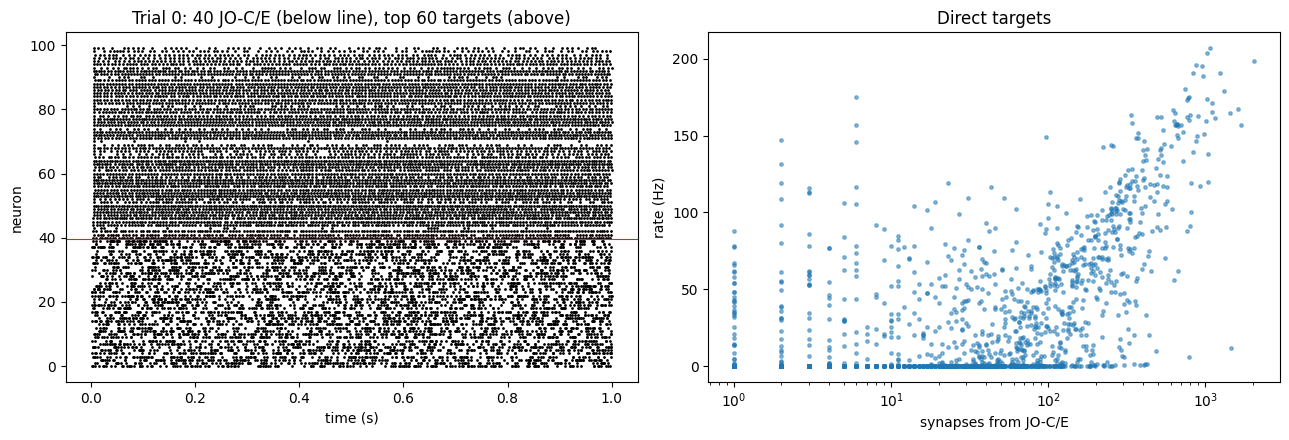

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

show = np.concatenate([JO[:40], t1.sort_values('syn_from_JO', ascending=False).index[:60]])
local = pd.Series(np.arange(len(net1.keep)), index=net1.keep).loc[show].to_numpy()
row = {l: r for r, l in enumerate(local)}
s = spk1[(spk1.trial == 0) & spk1.local.isin(local)]
ax[0].scatter(s.t, s.local.map(row), s=1, c='k')
ax[0].axhline(39.5, color='tab:red', lw=0.8)
ax[0].set(xlabel='time (s)', ylabel='neuron', title='Trial 0: 40 JO-C/E (below line), top 60 targets (above)')

ax[1].scatter(t1.syn_from_JO, t1.rate_hz, s=6, alpha=0.5)
ax[1].set(xscale='log', xlabel='synapses from JO-C/E', ylabel='rate (Hz)', title='Direct targets')
plt.tight_layout()
plt.savefig(DATA / 'check1_direct_targets.png', dpi=120)

---
### Cell 5: check 2 groups, sugar GRNs and MN9

In male-CNS, labellar taste neurons are typed by anatomy (LB…), not by taste. Tastekin, de Haan Vicente et al. 2026 assign **LB3b and LB3c** as sugar-sensing. MN9 is the pair 10331 (L) and 16949 (R), found in Cell 2.

In [6]:
types = ws.neurons['type'].astype(str)
lb = ws.neurons[(ws.neurons.cls == 'cb_sensory') & types.str.match(r'^LB')]
print("labellar (LB) sensory types:")
display(lb['type'].value_counts().sort_index().to_frame('neurons').T)

SUGAR = ws.by_type(r'^LB3(b|c)$', cls='cb_sensory')
MN9 = ws.by_type(r'^MN9$')
assert len(SUGAR) > 0, "no LB3b/LB3c found: send me the LB type list above"
print(f"sugar GRNs: {len(SUGAR)}")
display(ws.neurons.loc[SUGAR].groupby(['type', 'side'], dropna=False).size().to_frame('neurons'))
display(ws.neurons.loc[MN9, ['bodyId', 'type', 'side', 'nt_used']])

labellar (LB) sensory types:


type,LB1a,LB1b,LB1c,LB1d,LB1e,LB2a,LB2b,LB2c,LB2d,LB3,LB3a,LB3b,LB3c,LB3d,LB4a,LB4b
neurons,11,6,16,5,19,4,3,6,5,1,17,11,23,26,4,8


sugar GRNs: 34


,,neurons
type,side,
LB3b,NaN,11
LB3c,NaN,23


,bodyId,type,side,nt_used
13273,10331,MN9,L,acetylcholine
13385,16949,MN9,R,acetylcholine


### Cell 6: check 2 subnetwork

The full network doesn't fit in 4 GB, so this keeps neurons that lie on **short paths** from sugar GRNs to MN9: a neuron is kept if (hops from sugar) + (hops to MN9) ≤ L. The search counts only connections with ≥5 synapses; all connections among the kept neurons are simulated.

The cell starts at the shortest sugar → MN9 path length and adds one hop at a time while the subnetwork stays under ~2.5M connections.

Caveat: neurons off these paths are missing, including some inhibition, so MN9 may respond more strongly here than in the full network. The chosen `w_syn` gets confirmed on the full network on Colab later.

In [7]:
MAX_CONN = 2_500_000

on_path, d_fwd, d_bwd = ws.path_neurons(SUGAR, MN9, max_len=6, min_syn=5)
shortest = int(d_fwd[MN9][d_fwd[MN9] >= 0].min())
print(f"\nshortest sugar -> MN9 path: {shortest} hops "
      f"(MN9 L: {d_fwd[MN9[0]]}, R: {d_fwd[MN9[1]]})\n")

total = d_fwd.astype(int) + d_bwd
ok = (d_fwd >= 0) & (d_bwd >= 0)
sizes = []
for L in range(shortest, 7):
    k = np.union1d(np.flatnonzero(ok & (total <= L)), np.concatenate([SUGAR, MN9]))
    n_conn = len(ws.subnetwork(k)['w'])
    sizes.append((L, len(k), n_conn))
    print(f"L = {L}: {len(k):>7,} neurons, {n_conn:>10,} connections")
    if n_conn > MAX_CONN:
        break

L2, _, _ = [s_ for s_ in sizes if s_[2] <= MAX_CONN][-1]
keep2 = np.union1d(np.flatnonzero(ok & (total <= L2)), np.concatenate([SUGAR, MN9]))
sub2 = ws.subnetwork(keep2)
print(f"\nusing L = {L2}: {len(keep2):,} neurons, {len(sub2['w']):,} connections")
display(ws.neurons.loc[keep2, 'cls'].value_counts().head(10).to_frame('neurons'))

downstream of source:
  hop 1: +142 new, 176 total
  hop 2: +4,863 new, 5,039 total
  hop 3: +48,630 new, 53,669 total
  hop 4: +88,096 new, 141,765 total
  hop 5: +20,868 new, 162,633 total
  hop 6: +2,885 new, 165,518 total
upstream of target:
  hop 1: +98 new, 100 total
  hop 2: +3,336 new, 3,436 total
  hop 3: +40,806 new, 44,242 total
  hop 4: +95,476 new, 139,718 total
  hop 5: +25,048 new, 164,766 total
  hop 6: +2,788 new, 167,554 total

shortest sugar -> MN9 path: 2 hops (MN9 L: 2, R: 3)

L = 2:      40 neurons,        358 connections
L = 3:     212 neurons,      8,738 connections
L = 4:   1,414 neurons,    159,022 connections
L = 5:   6,004 neurons,    818,603 connections
L = 6:  30,838 neurons,  5,818,013 connections

using L = 5: 6,004 neurons, 818,603 connections


,neurons
cls,
cb_intrinsic,2448
vnc_intrinsic,1189
ascending_neuron,798
cb_sensory,794
descending_neuron,559
cb_motor,48
vnc_sensory,39
sensory_ascending,34
visual_projection,21


### Cell 7: check 2 simulation

Stimulate all LB3b/LB3c at 150 Hz (Shiu's default) and 50 Hz, 5 trials each, plus a no-stimulus baseline.

**Pass:** baseline silent, and MN9 fires under sugar stimulation. If MN9 is silent, that alone doesn't mean a bug: `w_syn` was tuned on FlyWire and may be too weak here, which the Step 5 sweep tests. A bug is if neurons one step downstream of sugar are silent too.

In [8]:
net2 = LIFNet(sub2, stim_global=SUGAR)
spk = net2.run(rate=0 * Hz, n_trials=1)
print(f"baseline spikes: {len(spk)} (should be 0)\n")

res2 = {}
for rate in [50, 150]:
    spk = net2.run(rate=rate * Hz, n_trials=5)
    r = net2.rates(spk, ws)
    res2[rate] = r
    print(f"  sugar GRN rate {r.loc[SUGAR, 'rate_hz'].mean():.0f} Hz | "
          f"MN9: " + ', '.join(f"{ws.neurons.side[i]} {r.rate_hz[i]:.1f} Hz" for i in MN9) +
          f" | subnetwork neurons firing: {(r.drop(SUGAR).rate_hz >= 1).mean():.1%}\n")

direct = ws.partners(SUGAR, 'out', min_syn=5).drop(SUGAR, errors='ignore')
direct = direct[direct.index.isin(keep2)]
r = res2[150]
print(f"direct sugar targets (>=5 syn) in subnetwork: {len(direct)}, firing >= 1 Hz: {(r.loc[direct.index, 'rate_hz'] >= 1).mean():.0%}")
print("\nmost active neurons at 150 Hz (excluding sugar GRNs):")
display(r.drop(SUGAR).sort_values('rate_hz', ascending=False).head(20))

built: 6,004 neurons, 818,603 connections, 0.1 s, peak memory 1.69 GB
1 trials × 1 s: 0.6 s, peak memory 1.69 GB
baseline spikes: 0 (should be 0)

5 trials × 1 s: 2.9 s, peak memory 1.69 GB
  sugar GRN rate 49 Hz | MN9: L 41.8 Hz, R 1.8 Hz | subnetwork neurons firing: 9.8%

5 trials × 1 s: 2.9 s, peak memory 1.69 GB
  sugar GRN rate 148 Hz | MN9: L 96.4 Hz, R 15.2 Hz | subnetwork neurons firing: 12.1%

direct sugar targets (>=5 syn) in subnetwork: 209, firing >= 1 Hz: 49%

most active neurons at 150 Hz (excluding sugar GRNs):


,bodyId,type,cls,nt_used,rate_hz
13287,11393,MN11D,cb_motor,acetylcholine,178.2
13284,11269,MN11D,cb_motor,acetylcholine,168.0
46817,512550,GNG038,cb_intrinsic,gaba,165.8
13419,21746,GNG038,cb_intrinsic,gaba,157.4
169440,10205,GNG003,cb_intrinsic,gaba,154.8
13203,533971,MNx01,cb_motor,glutamate,150.0
13472,43293,GNG041,cb_intrinsic,gaba,141.2
13353,15321,GNG042,cb_intrinsic,gaba,135.2
21916,16630,GNG479,cb_intrinsic,gaba,135.2
21904,15734,GNG042,cb_intrinsic,gaba,134.0


### Cell 8: check 2 raster

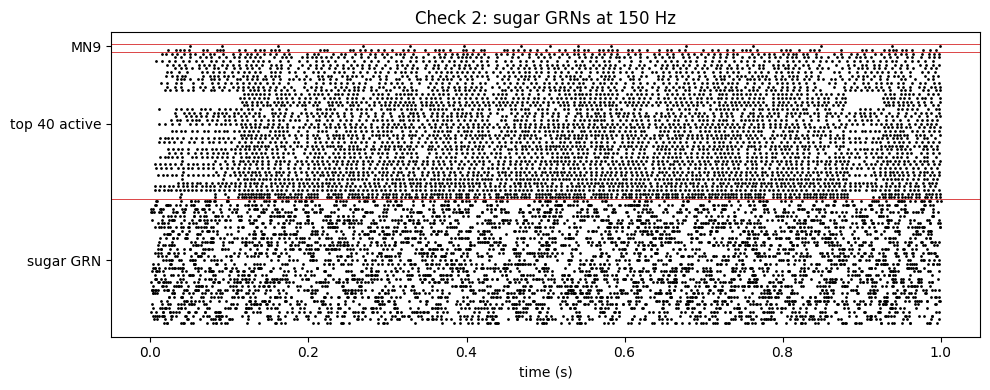

In [9]:
spk2 = net2.run(rate=150 * Hz, n_trials=1, verbose=False)
top2 = res2[150].drop(np.concatenate([SUGAR, MN9])).sort_values('rate_hz', ascending=False).index[:40]
fig, ax = plt.subplots(figsize=(10, 4))
raster(ax, spk2, net2, {'sugar GRN': SUGAR, 'top 40 active': top2, 'MN9': MN9})
ax.set_title('Check 2: sugar GRNs at 150 Hz')
plt.tight_layout(); plt.savefig(DATA / 'check2_sugar_MN9.png', dpi=120)

---
### Cell 9: check 3 subnetwork, JO-C/E → front-leg motor neurons

Same short-path rule as check 2, with the 68 descending candidates always included so their rates get recorded. The leg motor neurons are in the nerve cord, so expect longer paths than sugar → MN9.

In [10]:
sub3, L3, sizes3, d_jo = ws.path_subnetwork(JO, LEG_MN, max_len=7, min_syn=5, extra=DN_cand)
keep3 = sub3['keep']
print(f"subnetwork: {len(keep3):,} neurons, {len(sub3['w']):,} connections")
print(f"leg MNs reachable from JO-C/E within {L3} hops: {(d_jo[LEG_MN] >= 0).sum()} of {len(LEG_MN)}, "
      f"hop distance: {pd.Series(d_jo[LEG_MN]).value_counts().sort_index().to_dict()}")
display(ws.neurons.loc[keep3, 'cls'].value_counts().head(10).to_frame('neurons'))

downstream of source:
  hop 1: +1,165 new, 1,500 total
  hop 2: +18,202 new, 19,702 total
  hop 3: +104,130 new, 123,832 total
  hop 4: +37,829 new, 161,661 total
  hop 5: +3,777 new, 165,438 total
  hop 6: +436 new, 165,874 total
  hop 7: +148 new, 166,022 total
upstream of target:
  hop 1: +1,427 new, 1,508 total
  hop 2: +17,044 new, 18,552 total
  hop 3: +91,033 new, 109,585 total
  hop 4: +52,538 new, 162,123 total
  hop 5: +5,441 new, 167,564 total
  hop 6: +191 new, 167,755 total
  hop 7: +30 new, 167,785 total

shortest path: 2 hops; targets reachable within 7: 77/81

L = 2:     490 neurons,      5,411 connections
L = 3:   1,505 neurons,     82,396 connections
L = 4:   9,488 neurons,  1,409,715 connections
L = 5:  27,262 neurons,  4,687,805 connections

using L = 4
subnetwork: 9,488 neurons, 1,409,715 connections
leg MNs reachable from JO-C/E within 4 hops: 77 of 81, hop distance: {-1: 4, 2: 12, 3: 61, 4: 4}


,neurons
cls,
cb_intrinsic,3567
vnc_intrinsic,3094
descending_neuron,905
ascending_neuron,750
cb_sensory,501
visual_projection,375
vnc_motor,88
vnc_sensory,76
visual_centrifugal,56


### Cell 10: check 3 simulation

**Readout question:** which of the 68 descending candidates fire, and do the front-leg motor neurons follow?

In [11]:
net3 = LIFNet(sub3, stim_global=JO)
spk = net3.run(rate=0 * Hz, n_trials=1)
print(f"baseline spikes: {len(spk)} (should be 0)\n")

spk3 = net3.run(n_trials=5)
r3 = net3.rates(spk3, ws)

dn = shortlist.query("group == 'middle_descending'")[['bodyId', 'type', 'side', 'role', 'score']].copy()
dn['idx'] = g2i.loc[dn.bodyId].to_numpy()
dn['rate_hz'] = r3.loc[dn.idx, 'rate_hz'].to_numpy()
dn['hops_from_JO'] = d_jo[dn.idx]
dn['fired'] = dn.rate_hz >= 1

mn_r = r3.loc[LEG_MN, 'rate_hz']
all_dn = r3[r3.cls == 'descending_neuron']
print(f"JO-C/E: {r3.loc[JO, 'rate_hz'].mean():.0f} Hz")
print(f"descending candidates firing: {dn.fired.sum()} of {len(dn)}")
print(f"all descending neurons in subnetwork firing: {(all_dn.rate_hz >= 1).sum()} of {len(all_dn)}")
print(f"front-leg MNs firing: {(mn_r >= 1).sum()} of {len(LEG_MN)}, mean {mn_r.mean():.1f} Hz, max {mn_r.max():.1f} Hz")
print(f"subnetwork neurons firing: {(r3.drop(JO).rate_hz >= 1).mean():.1%}\n")

display(dn.groupby('role').agg(candidates=('fired', 'size'), fired=('fired', 'sum'), mean_rate=('rate_hz', 'mean')))
display(dn.sort_values('rate_hz', ascending=False).head(25))
print("most active front-leg MNs:")
display(r3.loc[LEG_MN].sort_values('rate_hz', ascending=False).head(10))
print("most active descending neurons not in the candidate list:")
display(all_dn.drop(dn.idx, errors='ignore').sort_values('rate_hz', ascending=False).head(10))

built: 9,488 neurons, 1,409,715 connections, 0.1 s, peak memory 1.75 GB
1 trials × 1 s: 0.7 s, peak memory 1.75 GB
baseline spikes: 0 (should be 0)

5 trials × 1 s: 5.0 s, peak memory 1.75 GB
JO-C/E: 147 Hz
descending candidates firing: 39 of 68
all descending neurons in subnetwork firing: 271 of 905
front-leg MNs firing: 11 of 81, mean 7.9 Hz, max 122.0 Hz
subnetwork neurons firing: 25.3%



,candidates,fired,mean_rate
role,,,
bridge,6,6,104.033333
input-side,44,23,38.009091
output-side,18,10,54.855556


,bodyId,type,side,role,score,idx,rate_hz,hops_from_JO,fired
349,10118,DNb05,L,bridge,0.021624,61300,188.6,1,True
350,10065,DNb05,R,output-side,0.012457,62377,184.2,1,True
391,10048,DNp18,L,input-side,0.031636,151286,173.6,1,True
357,10446,DNp73,L,input-side,0.015711,74544,161.4,1,True
354,15653,DNge012,L,output-side,0.016982,72093,151.8,2,True
356,10026,DNp18,R,input-side,0.016705,72268,138.2,1,True
373,524190,DNge012,R,output-side,0.011175,106893,137.6,2,True
346,14537,DNge078,L,output-side,0.015832,55117,134.8,2,True
335,36541,DNge078,R,output-side,0.029522,40457,134.4,2,True
386,10587,DNge011,L,output-side,0.019560,135329,130.0,2,True


most active front-leg MNs:


,bodyId,type,cls,nt_used,rate_hz
34657,806898,Fe reductor MN,vnc_motor,acetylcholine,122.0
34658,811652,Fe reductor MN,vnc_motor,acetylcholine,121.6
37368,804941,Fe reductor MN,vnc_motor,acetylcholine,105.8
99564,805598,Fe reductor MN,vnc_motor,acetylcholine,82.0
1793,1050111955,Ta levator MN,vnc_motor,acetylcholine,53.8
1377,800636,Ti extensor MN,vnc_motor,acetylcholine,43.2
35536,815678,Ti extensor MN,vnc_motor,acetylcholine,38.6
15431,810541,Ta levator MN,vnc_motor,acetylcholine,32.8
162558,815344,Ti extensor MN,vnc_motor,acetylcholine,28.0
16497,828939,Tr flexor MN,vnc_motor,acetylcholine,6.2


most active descending neurons not in the candidate list:


,bodyId,type,cls,nt_used,rate_hz
158773,12092,DNge027,descending_neuron,acetylcholine,190.0
137612,524470,DNbe001,descending_neuron,acetylcholine,188.4
163764,11352,DNge027,descending_neuron,acetylcholine,176.0
44661,14098,DNge044,descending_neuron,acetylcholine,170.8
52314,10536,DNg29,descending_neuron,acetylcholine,170.4
154859,10740,DNge143,descending_neuron,gaba,167.6
119810,10499,DNge039,descending_neuron,acetylcholine,166.2
107820,13178,DNge039,descending_neuron,acetylcholine,166.0
54089,12170,DNge044,descending_neuron,acetylcholine,165.8
52934,10469,DNbe001,descending_neuron,acetylcholine,165.8


### Cell 11: check 3 raster and pruned descending list

saved dn_pruned_week2.csv: 39 descending neurons


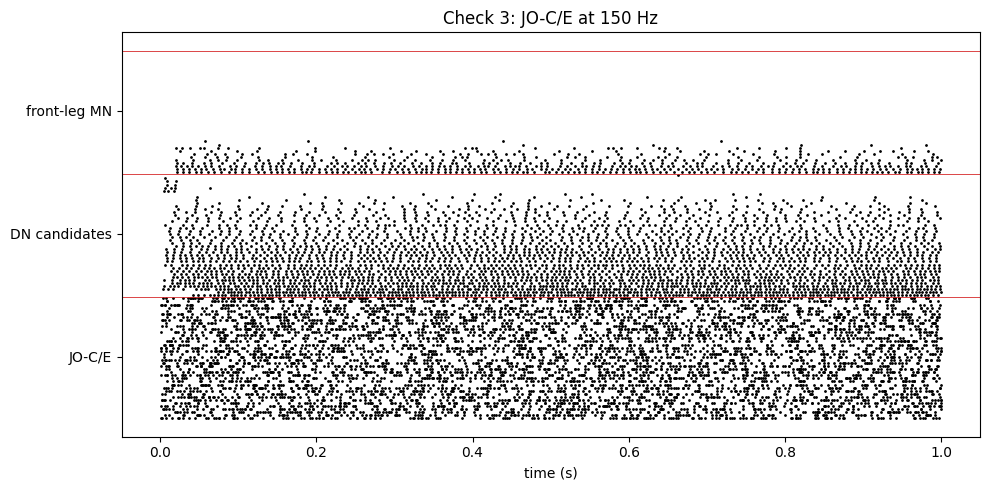

In [12]:
fired_dn = dn[dn.fired].sort_values('rate_hz', ascending=False)
fired_dn.to_csv(DATA / 'dn_pruned_week2.csv', index=False)
print(f"saved dn_pruned_week2.csv: {len(fired_dn)} descending neurons")

spk = net3.run(n_trials=1, verbose=False)
fig, ax = plt.subplots(figsize=(10, 5))
raster(ax, spk, net3, {'JO-C/E': JO, 'DN candidates': dn.sort_values('rate_hz', ascending=False).idx,
                       'front-leg MN': mn_r.sort_values(ascending=False).index})
ax.set_title('Check 3: JO-C/E at 150 Hz')
plt.tight_layout(); plt.savefig(DATA / 'check3_JO_DN_MN.png', dpi=120)

---
### Cell 12: check 4, shuffled control

Rewire each subnetwork randomly, keeping every neuron's number of inputs and outputs and each connection's weight and sign. Only *who connects to whom* changes. 3 shuffles × 5 trials each.

**Pass:** the target responses (MN9; descending candidates and leg MNs) drop sharply in the shuffled versions. That shows the specific wiring, not just the amount of excitation, produces the response.

In [13]:
def summary2(r):
    return dict(MN9_L=r.rate_hz[MN9[0]], MN9_R=r.rate_hz[MN9[1]],
                frac_firing=(r.drop(SUGAR).rate_hz >= 1).mean())

def summary3(r):
    return dict(DN_cand_firing=int((r.loc[dn.idx, 'rate_hz'] >= 1).sum()),
                DN_cand_mean_hz=r.loc[dn.idx, 'rate_hz'].mean(),
                legMN_firing=int((r.loc[LEG_MN, 'rate_hz'] >= 1).sum()),
                legMN_mean_hz=r.loc[LEG_MN, 'rate_hz'].mean(),
                frac_firing=(r.drop(JO).rate_hz >= 1).mean())

rows = [dict(check='2 sugar→MN9', network='real', **summary2(res2[150])),
        dict(check='3 JO→DN→MN', network='real', **summary3(r3))]
for s in range(3):
    n = LIFNet(shuffle_sub(sub2, seed=s), stim_global=SUGAR, verbose=False)
    rows.append(dict(check='2 sugar→MN9', network=f'shuffled {s}', **summary2(n.rates(n.run(n_trials=5, verbose=False), ws))))
    n = LIFNet(shuffle_sub(sub3, seed=s), stim_global=JO, verbose=False)
    rows.append(dict(check='3 JO→DN→MN', network=f'shuffled {s}', **summary3(n.rates(n.run(n_trials=5, verbose=False), ws))))
    del n
    print(f"shuffle {s} done, peak memory {peak_mem_gb():.2f} GB")

shuf = pd.DataFrame(rows).sort_values(['check', 'network']).set_index(['check', 'network'])
shuf.to_csv(DATA / 'check4_shuffle.csv')
display(shuf.round(2))

shuffle 0 done, peak memory 1.75 GB
shuffle 1 done, peak memory 1.75 GB
shuffle 2 done, peak memory 1.75 GB


MN9_L  MN9_R  frac_firing  DN_cand_firing  \
check       network                                                 
2 sugar→MN9 real         96.4   15.2         0.12             NaN   
            shuffled 0   90.0   45.2         0.62             NaN   
            shuffled 1   89.0    0.0         0.59             NaN   
            shuffled 2   23.4    9.6         0.58             NaN   
3 JO→DN→MN  real          NaN    NaN         0.25            39.0   
            shuffled 0    NaN    NaN         0.66            45.0   
            shuffled 1    NaN    NaN         0.64            53.0   
            shuffled 2    NaN    NaN         0.67            50.0   

                        DN_cand_mean_hz  legMN_firing  legMN_mean_hz  
check       network                                                   
2 sugar→MN9 real                    NaN           NaN            NaN  
            shuffled 0              NaN           NaN            NaN  
            shuffled 1              NaN           NaN            NaN  
            shuffled 2              NaN           NaN            NaN  
3 JO→DN→MN  real                  48.29          11.0           7.86  
            shuffled 0            39.59          50.0          26.23  
            shuffled 1            35.16          51.0          18.88  
            shuffled 2            37.89          49.0          25.70

### Cell 13: check 4, activity-matched shuffled control

Cell 12 showed that shuffled networks run away (about 60% of neurons firing vs 12–25% with real wiring), which makes the target comparison unfair. Here each shuffled network's `w_syn` is turned down until the **same share of neurons fires as in the real network**, by bisection on the scale. Then the target responses are compared.

**Pass:** at matched overall activity, MN9 (check 2) and the descending candidates and leg MNs (check 3) respond clearly less in the shuffled networks than in the real one.

In [14]:
def frac_firing(net, stim, scale, trials=1):
    r = net.rates(net.run(n_trials=trials, w_scale=scale, verbose=False), ws)
    return r, (r.drop(stim).rate_hz >= 1).mean()

def matched_shuffles(sub, stim, target_frac, summ, label, n_shuffles=3):
    rows = []
    for s in range(n_shuffles):
        n = LIFNet(shuffle_sub(sub, seed=s), stim_global=stim, verbose=False)
        lo, hi = 0.02, 1.0
        for _ in range(9):                       # bisection on a log scale
            mid = (lo * hi) ** 0.5
            _, f = frac_firing(n, stim, mid)
            lo, hi = (lo, mid) if f > target_frac else (mid, hi)
        scale = (lo * hi) ** 0.5
        r, f = frac_firing(n, stim, scale, trials=5)
        rows.append(dict(check=label, network=f'shuffled {s}, matched', w_scale=round(scale, 3), **summ(r)))
        del n
        print(f"{label} shuffle {s}: w_scale {scale:.3f}, firing {f:.1%} (target {target_frac:.1%})")
    return rows

rows = [dict(check='2 sugar→MN9', network='real', w_scale=1.0, **summary2(res2[150])),
        dict(check='3 JO→DN→MN', network='real', w_scale=1.0, **summary3(r3))]
rows += matched_shuffles(sub2, SUGAR, summary2(res2[150])['frac_firing'], summary2, '2 sugar→MN9')
rows += matched_shuffles(sub3, JO, summary3(r3)['frac_firing'], summary3, '3 JO→DN→MN')

matched = pd.DataFrame(rows).set_index(['check', 'network'])
matched.to_csv(DATA / 'check4_shuffle_matched.csv')
display(matched.round(2))

2 sugar→MN9 shuffle 0: w_scale 0.734, firing 9.4% (target 12.1%)
2 sugar→MN9 shuffle 1: w_scale 0.768, firing 13.6% (target 12.1%)
2 sugar→MN9 shuffle 2: w_scale 0.792, firing 10.9% (target 12.1%)
3 JO→DN→MN shuffle 0: w_scale 0.478, firing 24.1% (target 25.3%)
3 JO→DN→MN shuffle 1: w_scale 0.516, firing 23.5% (target 25.3%)
3 JO→DN→MN shuffle 2: w_scale 0.501, firing 23.5% (target 25.3%)


w_scale  MN9_L  MN9_R  frac_firing  \
check       network                                                   
2 sugar→MN9 real                    1.00   96.4   15.2         0.12   
3 JO→DN→MN  real                    1.00    NaN    NaN         0.25   
2 sugar→MN9 shuffled 0, matched     0.73    0.0    0.0         0.09   
            shuffled 1, matched     0.77    4.6    0.0         0.14   
            shuffled 2, matched     0.79    0.0    0.0         0.11   
3 JO→DN→MN  shuffled 0, matched     0.48    NaN    NaN         0.24   
            shuffled 1, matched     0.52    NaN    NaN         0.23   
            shuffled 2, matched     0.50    NaN    NaN         0.24   

                                 DN_cand_firing  DN_cand_mean_hz  \
check       network                                                
2 sugar→MN9 real                            NaN              NaN   
3 JO→DN→MN  real                           39.0            48.29   
2 sugar→MN9 shuffled 0, matched             NaN              NaN   
            shuffled 1, matched             NaN              NaN   
            shuffled 2, matched             NaN              NaN   
3 JO→DN→MN  shuffled 0, matched            28.0             6.77   
            shuffled 1, matched            30.0             7.71   
            shuffled 2, matched            25.0             5.58   

                                 legMN_firing  legMN_mean_hz  
check       network                                           
2 sugar→MN9 real                          NaN            NaN  
3 JO→DN→MN  real                         11.0           7.86  
2 sugar→MN9 shuffled 0, matched           NaN            NaN  
            shuffled 1, matched           NaN            NaN  
            shuffled 2, matched           NaN            NaN  
3 JO→DN→MN  shuffled 0, matched          14.0           1.54  
            shuffled 1, matched          18.0           2.25  
            shuffled 2, matched          15.0           2.97

---
## Step 5: `w_syn` sweep

Only `w_syn` changes. Threshold, time constants and stimulus strength stay at Shiu's values. Each scale multiplies Shiu's 0.275 mV.

At each scale, on both subnetworks (sugar at 150 Hz, JO-C/E at 150 Hz, 3 trials each):
- **target response:** MN9 L/R; descending candidates (number firing, mean rate); front-leg MNs (number firing, mean rate)
- **runaway:** share of all subnetwork neurons firing ≥1 Hz

**Selection rule, fixed before looking at the results:** the *lowest* scale at which MN9 L ≥ 20 Hz **and** the descending candidates' mean rate ≥ 20 Hz, provided neither subnetwork has more than 30% of its neurons firing. Lowest, because more weight than needed only pushes the network toward runaway.

Caveat: runaway on a subnetwork understates runaway on the full network. The chosen scale gets confirmed on the full network on Colab.

In [15]:
SCALES = [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0]
N_TRIALS = 3

rows = []
for sc in SCALES:
    a = summary2(net2.rates(net2.run(rate=150 * Hz, n_trials=N_TRIALS, w_scale=sc, verbose=False), ws))
    b = summary3(net3.rates(net3.run(rate=150 * Hz, n_trials=N_TRIALS, w_scale=sc, verbose=False), ws))
    rows.append(dict(w_scale=sc, w_syn_mV=round(0.275 * sc, 4),
                     MN9_L=a['MN9_L'], MN9_R=a['MN9_R'], firing_sugar_sub=a['frac_firing'],
                     DN_cand_firing=b['DN_cand_firing'], DN_cand_mean_hz=b['DN_cand_mean_hz'],
                     legMN_firing=b['legMN_firing'], legMN_mean_hz=b['legMN_mean_hz'],
                     firing_JO_sub=b['frac_firing']))
    print(f"scale {sc:4}: MN9 L {a['MN9_L']:6.1f} Hz | DN cand {b['DN_cand_mean_hz']:6.1f} Hz | "
          f"leg MN {b['legMN_firing']:2d} firing | runaway {a['frac_firing']:.0%} / {b['frac_firing']:.0%}")

sweep = pd.DataFrame(rows)
sweep.to_csv(DATA / 'wsyn_sweep_subnetworks.csv', index=False)

ok = sweep[(sweep.MN9_L >= 20) & (sweep.DN_cand_mean_hz >= 20) &
           (sweep.firing_sugar_sub <= 0.30) & (sweep.firing_JO_sub <= 0.30)]
CHOSEN = float(ok.w_scale.min()) if len(ok) else None
print(f"\nscales meeting the rule: {ok.w_scale.tolist()}")
print(f"chosen w_scale: {CHOSEN}" + (f"  (w_syn = {0.275 * CHOSEN:.4f} mV)" if CHOSEN else "  -- none: send me the table"))
display(sweep.round(2))

scale 0.25: MN9 L    0.0 Hz | DN cand   16.8 Hz | leg MN  0 firing | runaway 1% / 5%
scale 0.35: MN9 L    0.0 Hz | DN cand   24.1 Hz | leg MN  4 firing | runaway 1% / 8%
scale  0.5: MN9 L    3.0 Hz | DN cand   31.7 Hz | leg MN  8 firing | runaway 2% / 12%
scale  0.7: MN9 L   52.7 Hz | DN cand   39.8 Hz | leg MN  9 firing | runaway 7% / 20%
scale  1.0: MN9 L  100.0 Hz | DN cand   48.2 Hz | leg MN 11 firing | runaway 12% / 26%
scale  1.4: MN9 L  145.0 Hz | DN cand   56.8 Hz | leg MN 11 firing | runaway 20% / 31%
scale  2.0: MN9 L  157.3 Hz | DN cand   66.1 Hz | leg MN 12 firing | runaway 32% / 36%
scale  2.8: MN9 L  199.3 Hz | DN cand   73.6 Hz | leg MN 13 firing | runaway 37% / 40%
scale  4.0: MN9 L  250.3 Hz | DN cand   79.7 Hz | leg MN 17 firing | runaway 39% / 45%

scales meeting the rule: [0.7, 1.0]
chosen w_scale: 0.7  (w_syn = 0.1925 mV)


,w_scale,w_syn_mV,MN9_L,MN9_R,firing_sugar_sub,DN_cand_firing,DN_cand_mean_hz,legMN_firing,legMN_mean_hz,firing_JO_sub
0,0.25,0.07,0.00,0.00,0.01,27,16.84,0,0.00,0.05
1,0.35,0.10,0.00,0.00,0.01,36,24.08,4,0.34,0.08
2,0.50,0.14,3.00,0.00,0.02,36,31.74,8,3.51,0.12
3,0.70,0.19,52.67,0.00,0.07,38,39.81,9,5.82,0.20
4,1.00,0.28,100.00,15.00,0.12,39,48.16,11,7.84,0.26
5,1.40,0.38,145.00,39.33,0.20,39,56.83,11,9.33,0.31
6,2.00,0.55,157.33,58.33,0.32,39,66.10,12,9.71,0.36
7,2.80,0.77,199.33,78.00,0.37,39,73.57,13,9.89,0.40
8,4.00,1.10,250.33,126.33,0.39,43,79.68,17,9.14,0.45


### Cell 15: sweep plot and saved choice

{
  "w_scale": 0.7,
  "w_syn_mV": 0.1925,
  "status": "chosen on subnetworks; confirm on full network",
  "rule": "lowest scale with MN9_L >= 20 Hz and DN candidate mean >= 20 Hz, both subnetworks <= 30% firing",
  "weights": "weights_male-cns_v1.0"
}


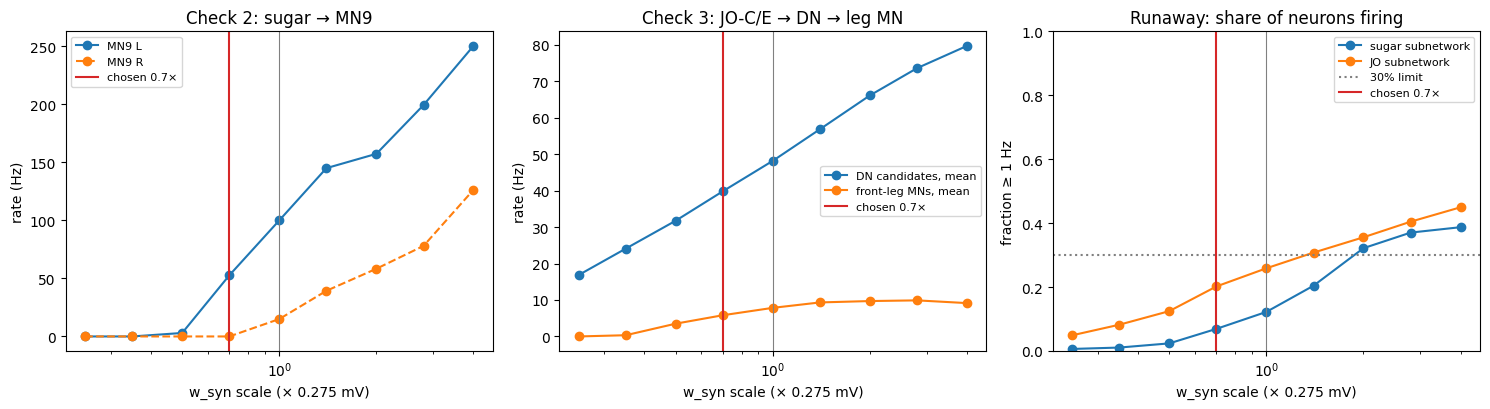

In [16]:
import json
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].plot(sweep.w_scale, sweep.MN9_L, 'o-', label='MN9 L')
ax[0].plot(sweep.w_scale, sweep.MN9_R, 'o--', label='MN9 R')
ax[0].set(title='Check 2: sugar → MN9', ylabel='rate (Hz)')
ax[1].plot(sweep.w_scale, sweep.DN_cand_mean_hz, 'o-', label='DN candidates, mean')
ax[1].plot(sweep.w_scale, sweep.legMN_mean_hz, 'o-', label='front-leg MNs, mean')
ax[1].set(title='Check 3: JO-C/E → DN → leg MN', ylabel='rate (Hz)')
ax[2].plot(sweep.w_scale, sweep.firing_sugar_sub, 'o-', label='sugar subnetwork')
ax[2].plot(sweep.w_scale, sweep.firing_JO_sub, 'o-', label='JO subnetwork')
ax[2].axhline(0.30, color='grey', ls=':', label='30% limit')
ax[2].set(title='Runaway: share of neurons firing', ylabel='fraction ≥ 1 Hz', ylim=(0, 1))
for a in ax:
    a.set(xscale='log', xlabel='w_syn scale (× 0.275 mV)')
    a.axvline(1.0, color='grey', lw=0.8)
    if CHOSEN:
        a.axvline(CHOSEN, color='tab:red', lw=1.5, label=f'chosen {CHOSEN}×')
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(DATA / 'wsyn_sweep.png', dpi=120)

if CHOSEN:
    choice = dict(w_scale=CHOSEN, w_syn_mV=0.275 * CHOSEN, status='chosen on subnetworks; confirm on full network',
                  rule='lowest scale with MN9_L >= 20 Hz and DN candidate mean >= 20 Hz, both subnetworks <= 30% firing',
                  weights=str(ws.folder.name))
    (DATA / 'wsyn_choice.json').write_text(json.dumps(choice, indent=2))
    print(json.dumps(choice, indent=2))